# Dispersion Pitch EDA: when is the correlation risk premium worth collecting?

**Background.** Index vol depends on single-stock vols *and* how much the stocks move together. Cboe's **COR1M**
backs out the correlation of the top 50 S&P 500 stocks that option prices imply over the next 30 days. A dispersion
trade (short index vol, long single-stock vol) is, to first order, **short implied correlation**: it earns
implied − realized correlation, like a correlation swap. Historically implied > realized (investors overpay for
index puts; funds overwrite single-stock calls), but correlation spikes in crashes, so the trade is crash insurance
sold to others.

**Questions.**
1. Is the premium (implied − next-month realized correlation) positive, and how bad are the losses?
2. Is it a risk premium, i.e. do losses come in market sell-offs?
3. Which conditions, known in advance, predict a bigger or smaller premium? (in-sample only)
4. At record-low implied correlation (July 2026: ~7), is it better to *buy* correlation?
5. Does a rule built in-sample work out of sample?

**Proxy trade.** A one-month correlation swap struck at COR1M: P&L (correlation points) = COR1M_t − realized
correlation over the next 21 trading days of the same kind of basket (top 50 by market cap, cap-weighted). Real
dispersion books trade options and pay much wider costs; see the cost sensitivity at the end.

**Split.** In-sample 2006–2017, out-of-sample 2018–2026 (includes Feb 2018 Volmageddon, COVID, 2022, March 2026).

## 1. Data

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data")
H1, H3, TOPN = 21, 63, 50
SPLIT = pd.Timestamp("2018-01-01")

cb = pd.read_csv(DATA / "cboe.csv", parse_dates=["date"]).pivot(index="date", columns="index", values="close")
st = pd.read_csv(DATA / "stocks.csv", parse_dates=["date"])
sh = pd.read_csv(DATA / "shares.csv").set_index("ticker").shares
close = st.pivot(index="date", columns="ticker", values="close")
adj = st.pivot(index="date", columns="ticker", values="adj_close")
cal = close.index[close.index >= "2006-01-03"]
R = adj.pct_change().reindex(cal)
spy = R.pop("SPY"); close = close.drop(columns="SPY")
names = [c for c in close.columns if c in sh.index]
cap = close.reindex(cal)[names] * sh[names]   # approximate market cap
R = R[cap.columns]
cb = cb.reindex(cal).ffill(limit=3)
print(f"{len(cal)} days {cal[0].date()}..{cal[-1].date()}, {R.shape[1]} stocks; COR1M now {cb.COR1M.iloc[-1]:.1f}")

5228 days 2006-01-03..2026-10-14, 136 stocks; COR1M now 9.0


## 2. Realized correlation
**What this does.** On each day $t$, take the 50 largest names by (approximate) market cap, with cap weights $w_i$
rescaled to sum to 1 over the 50 names. Over a window, with $\sigma_i$ each stock's realized vol and $\sigma_B$ the
**S&P 500 (SPY)** realized vol, the cap-weighted average correlation is

$$
\rho = \frac{\sigma_B^2 - \sum_{i=1}^{50} w_i^2 \sigma_i^2}{\left(\sum_{i=1}^{50} w_i \sigma_i\right)^2 - \sum_{i=1}^{50} w_i^2 \sigma_i^2}
$$

This is the same formula Cboe uses for COR with implied vols (Cboe white paper: SPX ATM implied vol vs a top-50 basket
of single-stock implied vols). Using the 50-stock basket's own vol for $\sigma_B$ instead gives a different quantity
that drifts as mega-caps decouple from the other 450 names. Computed over the **next** 21 days (what a trade struck at
$t$ realizes), the next 63 days, and the **past** 21 days (known at $t$).

**Check.** Names that were delisted/acquired (Celgene, Monsanto…) are missing, and market caps use today's share
count, so early baskets are approximate. If the proxy is good it should track COR1M closely in level and timing.

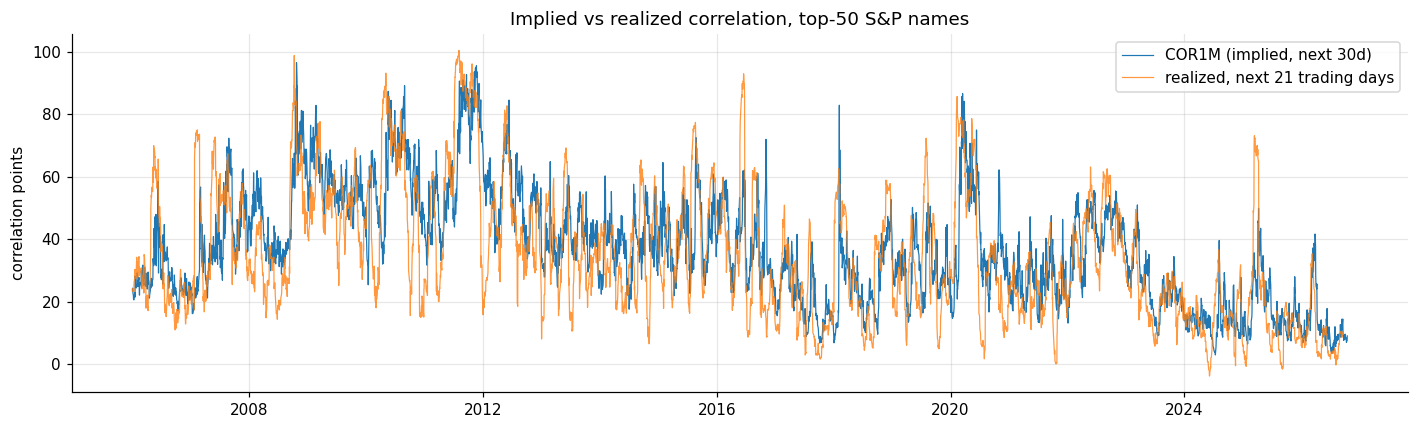

corr(COR1M, past realized) 0.76; corr(COR1M, next realized) 0.70
mean COR1M 37.1, mean next-21d realized 35.0


In [2]:
Rv, Cv, Sv = R.values, cap.values, spy.reindex(cal).values
def rcorr(i0, i1, i_rank):
    # realized cap-weighted correlation over rows i0..i1-1, basket = top-N by cap on row i_rank
    c = Cv[i_rank]; ok = ~np.isnan(c) & ~np.isnan(Rv[i0:i1]).any(axis=0)
    idx = np.where(ok)[0]
    if len(idx) < 30: return np.nan
    idx = idx[np.argsort(-c[idx])[:TOPN]]
    w = c[idx] / c[idx].sum(); X = Rv[i0:i1, idx]
    s = X.std(axis=0, ddof=1); sb = np.nanstd(Sv[i0:i1], ddof=1)   # index (SPY) vol, as in Cboe COR
    a, b = (w ** 2 * s ** 2).sum(), (w * s).sum()
    return (sb ** 2 - a) / (b ** 2 - a) * 100

n = len(cal)
fwd1 = np.array([rcorr(i + 1, i + 1 + H1, i) if i + 1 + H1 <= n else np.nan for i in range(n)])
fwd3 = np.array([rcorr(i + 1, i + 1 + H3, i) if i + 1 + H3 <= n else np.nan for i in range(n)])
past1 = np.array([rcorr(i - H1 + 1, i + 1, i) if i >= H1 else np.nan for i in range(n)])
df = pd.DataFrame({"cor1m": cb.COR1M, "cor3m": cb.COR3M, "cor10d": cb.COR10D, "vix": cb.VIX, "vix3m": cb.VIX3M,
                   "vvix": cb.VVIX, "dspx": cb.DSPX, "rc_fwd1": fwd1, "rc_fwd3": fwd3, "rc_past1": past1}, index=cal)
df["spy_fwd1"] = (1 + spy).rolling(H1).apply(np.prod, raw=True).shift(-H1) - 1
df["spy_rv_past"] = spy.rolling(H1).std() * np.sqrt(252) * 100
df["crp1"] = df.cor1m - df.rc_fwd1          # P&L of a short 1M correlation swap, correlation points
df["crp3"] = df.cor3m - df.rc_fwd3

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(df.index, df.cor1m, lw=0.8, label="COR1M (implied, next 30d)")
ax.plot(df.index, df.rc_fwd1, lw=0.8, alpha=0.8, label="realized, next 21 trading days")
ax.set_ylabel("correlation points"); ax.legend(); ax.set_title("Implied vs realized correlation, top-50 S&P names")
plt.tight_layout(); plt.show()
v = df[["cor1m", "rc_past1", "rc_fwd1"]].dropna()
print(f"corr(COR1M, past realized) {v.cor1m.corr(v.rc_past1):.2f}; corr(COR1M, next realized) {v.cor1m.corr(v.rc_fwd1):.2f}")
print(f"mean COR1M {v.cor1m.mean():.1f}, mean next-21d realized {v.rc_fwd1.mean():.1f}")

## 3. Q1: the premium and its losses
**What this does.** Non-overlapping monthly sample (every 21 trading days) of the short-correlation P&L.

                all  in-sample  out-of-sample
n            248.00     144.00         104.00
mean           1.79       3.19          -0.14
median         3.03       3.98           1.09
t              1.80       2.25          -0.11
hit            0.58       0.62           0.53
skew          -0.34      -0.14          -1.13
worst        -56.44     -51.35         -56.44
ann. Sharpe    0.40       0.65          -0.04

worst months (short correlation):
            cor1m  rc_fwd1   crp1  spy_fwd1
date                                       
2020-02-10  25.29    81.73 -56.44     -0.18
2007-02-05  21.95    73.30 -51.35     -0.04
2025-03-17  27.77    72.31 -44.54     -0.05
2016-06-08  44.94    89.27 -44.33      0.01
2015-08-07  34.81    75.37 -40.56     -0.05
2018-01-08   7.86    45.19 -37.33     -0.02
2011-07-06  46.28    77.87 -31.59     -0.10
2006-05-04  25.89    56.66 -30.77     -0.03


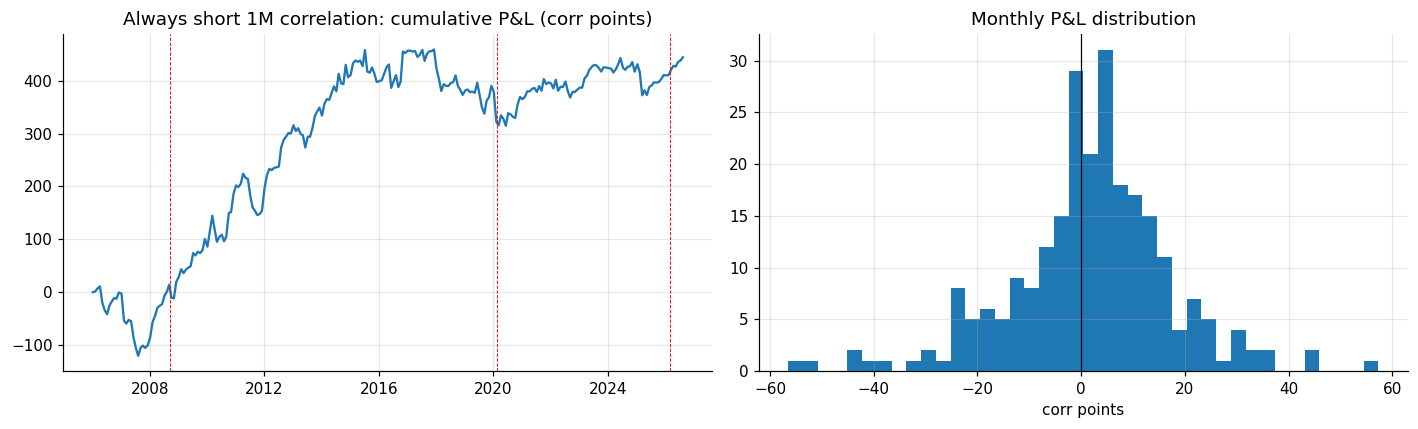

3M version (non-overlapping, n=82): mean 5.71, t 3.40, hit 76%


In [3]:
M = df.iloc[::H1].dropna(subset=["crp1"]).copy()
M["is"] = M.index < SPLIT
def describe(x):
    return pd.Series({"n": len(x), "mean": x.mean(), "median": x.median(), "t": x.mean() / x.std() * np.sqrt(len(x)),
                      "hit": (x > 0).mean(), "skew": stats.skew(x), "worst": x.min(), "ann. Sharpe": x.mean() / x.std() * np.sqrt(12)})
print(pd.DataFrame({"all": describe(M.crp1), "in-sample": describe(M[M["is"]].crp1),
                    "out-of-sample": describe(M[~M["is"]].crp1)}).round(2).to_string())
print("\nworst months (short correlation):")
print(M.nsmallest(8, "crp1")[["cor1m", "rc_fwd1", "crp1", "spy_fwd1"]].round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(M.index, M.crp1.cumsum()); ax[0].set_title("Always short 1M correlation: cumulative P&L (corr points)")
for d in ["2008-09-15", "2020-02-24", "2026-03-02"]: ax[0].axvline(pd.Timestamp(d), c="r", lw=0.6, ls="--")
ax[1].hist(M.crp1, bins=40); ax[1].axvline(0, c="k", lw=0.8); ax[1].set_title("Monthly P&L distribution"); ax[1].set_xlabel("corr points")
plt.tight_layout(); plt.show()
m3 = df.iloc[::H3].dropna(subset=["crp3"]).crp3
print(f"3M version (non-overlapping, n={len(m3)}): mean {m3.mean():.2f}, t {m3.mean() / m3.std() * np.sqrt(len(m3)):.2f}, hit {(m3 > 0).mean():.0%}")

## 4. Q2: is it a risk premium?
**Test.** If short correlation is crash insurance, its losses should come when the market falls. Regress monthly P&L on
the S&P return over the same window, and compare P&L in down vs up markets.

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2318      0.965      0.240      0.810      -1.660       2.124
spy_fwd1       1.5843      0.314      5.050      0.000       0.969       2.199
             mean  count
mkt                     
(-100, -5] -10.20     20
(-5, -2]   -12.44     32
(-2, 0]     -2.44     26
(0, 2]       1.95     65
(2, 5]       6.75     72
(5, 100]    15.07     33


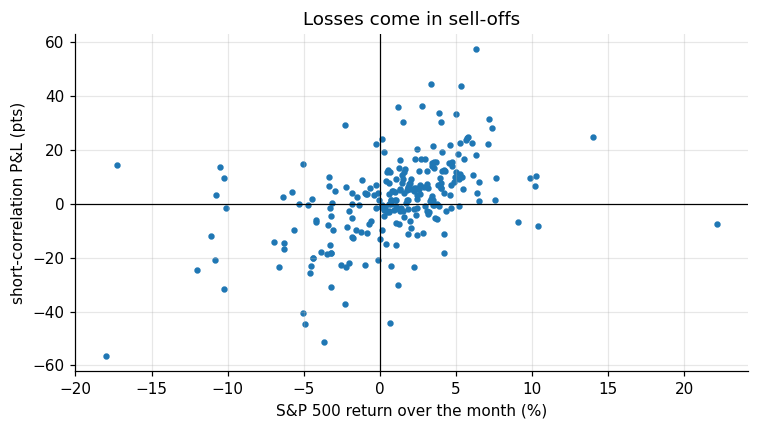

In [4]:
f = sm.OLS(M.crp1, sm.add_constant(M.spy_fwd1 * 100)).fit(cov_type="HC1")
print(f.summary().tables[1])
M["mkt"] = pd.cut(M.spy_fwd1 * 100, [-100, -5, -2, 0, 2, 5, 100])
g = M.groupby("mkt", observed=True).crp1.agg(["mean", "count"])
print(g.round(2).to_string())
plt.figure(figsize=(7, 4)); plt.scatter(M.spy_fwd1 * 100, M.crp1, s=10)
plt.axhline(0, c="k", lw=0.8); plt.axvline(0, c="k", lw=0.8)
plt.xlabel("S&P 500 return over the month (%)"); plt.ylabel("short-correlation P&L (pts)"); plt.title("Losses come in sell-offs")
plt.tight_layout(); plt.show()

## 5. Q3: what predicts the premium? (in-sample only)
**Candidate signals, all known at t.**
* `cor1m`: level of implied correlation.
* `carry`: COR1M − past-21d realized correlation (how rich implied is vs what is happening now).
* `vix`: index implied vol. `vix_slope`: VIX3M / VIX − 1 (> 0 calm contango, < 0 stress).
* `cor_slope`: COR3M − COR1M (correlation term structure).
* `earn`: share of the next 21 days that fall in peak earnings season (days 10–45 after quarter end), when stocks
  move on their own news and realized correlation should be low.

   signal   n  spearman     p     Q1     Q3     Q5  Kruskal H  p(KW)
    cor1m 144     0.208 0.012 -1.655 -1.109  7.397     11.913  0.018
    carry 143     0.028 0.742  3.149  2.909  3.882      0.230  0.994
      vix 144     0.202 0.015 -3.433  6.087  3.903     10.990  0.027
vix_slope  99    -0.055 0.590  7.952  6.306 -0.180      2.952  0.566
cor_slope 144     0.021 0.805  3.862  3.211  5.422      1.957  0.744
     earn 144     0.039 0.644  6.763 -0.728  3.180      5.996  0.199


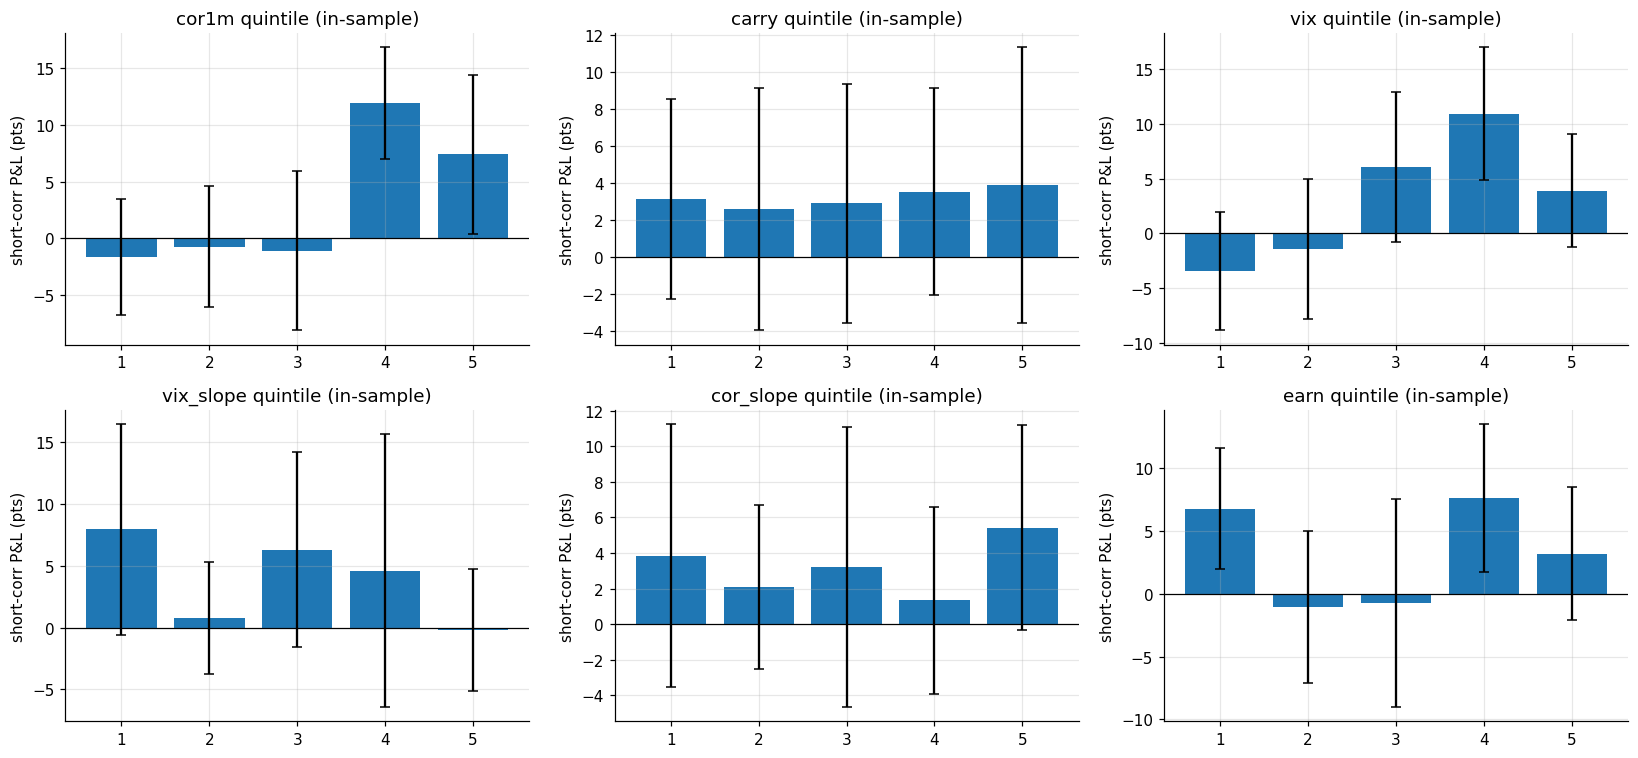

In [5]:
qend = lambda d: (d - pd.offsets.QuarterEnd(0) if d.is_quarter_end else d - pd.offsets.QuarterEnd(1))
in_earn = pd.Series([10 <= (d - qend(d)).days <= 45 for d in cal], index=cal).astype(float)
df["earn"] = in_earn.rolling(H1).mean().shift(-H1)       # calendar: known in advance
df["carry"] = df.cor1m - df.rc_past1
df["vix_slope"] = df.vix3m / df.vix - 1
df["cor_slope"] = df.cor3m - df.cor1m
M = df.iloc[::H1].dropna(subset=["crp1"]).copy(); M["is"] = M.index < SPLIT
IS = M[M["is"]]
SIGS = ["cor1m", "carry", "vix", "vix_slope", "cor_slope", "earn"]
rows = []
for s in SIGS:
    d = IS.dropna(subset=[s])
    r, p = stats.spearmanr(d[s], d.crp1)
    q = pd.qcut(d[s].rank(method="first"), 5, labels=False) + 1
    gm = d.groupby(q).crp1.mean()
    H, pk = stats.kruskal(*[d.crp1[q == k] for k in range(1, 6)])
    rows.append({"signal": s, "n": len(d), "spearman": r, "p": p, "Q1": gm[1], "Q3": gm[3], "Q5": gm[5], "Kruskal H": H, "p(KW)": pk})
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, s in zip(ax.flat, SIGS):
    d = IS.dropna(subset=[s]); q = pd.qcut(d[s].rank(method="first"), 5, labels=False) + 1
    g = d.groupby(q).crp1
    a.bar(g.mean().index, g.mean(), yerr=g.sem() * 1.96, capsize=3); a.axhline(0, c="k", lw=0.8)
    a.set_title(f"{s} quintile (in-sample)"); a.set_ylabel("short-corr P&L (pts)")
plt.tight_layout(); plt.show()

**Joint model.** Regress the premium on the signals together (in-sample, HC1 errors) to see which carry independent
information. Then check the sign of each slope out of sample.

In [6]:
JS = ["carry", "vix_slope", "cor_slope", "earn", "cor1m"]
d = IS.dropna(subset=JS)
fi = sm.OLS(d.crp1, sm.add_constant(d[JS])).fit(cov_type="HC1")
print("in-sample:"); print(fi.summary().tables[1])
o = M[~M["is"]].dropna(subset=JS)
fo = sm.OLS(o.crp1, sm.add_constant(o[JS])).fit(cov_type="HC1")
print("out-of-sample (same model re-fitted, for sign stability only):"); print(fo.summary().tables[1])

in-sample:
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -18.9204     11.032     -1.715      0.086     -40.542       2.701
carry          0.0501      0.121      0.415      0.678      -0.187       0.287
vix_slope     18.8781     32.694      0.577      0.564     -45.200      82.957
cor_slope      0.2683      0.740      0.363      0.717      -1.181       1.718
earn           6.2054      9.479      0.655      0.513     -12.374      24.784
cor1m          0.3601      0.157      2.288      0.022       0.052       0.669
out-of-sample (same model re-fitted, for sign stability only):
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -13.0605      6.989     -1.869      0.062     -26.759       0.638
carry         -0.0043      0.136     -0.032      0.975   

## 6. Q4: buy correlation when it is very cheap?
**What this does.** Rank COR1M against its own history *up to that day* (expanding percentile, no look-ahead). When it
is in the bottom decile, is the short premium small or negative, so that buying correlation pays?

In [7]:
df["cor_pct"] = df.cor1m.expanding(min_periods=252).apply(lambda x: (x[:-1] < x[-1]).mean(), raw=True)
M = df.iloc[::H1].dropna(subset=["crp1"]).copy(); M["is"] = M.index < SPLIT
M["pct_b"] = pd.cut(M.cor_pct, [0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0], include_lowest=True)
g = M.groupby("pct_b", observed=True).crp1.agg(["mean", "median", "count", lambda x: (x > 0).mean()])
g.columns = ["mean", "median", "n", "share short wins"]
print(g.round(2).to_string())
low = M[M.cor_pct < 0.1].crp1
print(f"\nbottom decile: mean {low.mean():+.2f}, t {low.mean() / low.std() * np.sqrt(len(low)):+.2f}, worst for a short {low.min():+.1f}")
print(f"today: COR1M {df.cor1m.iloc[-1]:.1f}, percentile vs history {df.cor_pct.iloc[-1]:.0%}; carry {df.carry.dropna().iloc[-1]:+.1f}")

                mean  median   n  share short wins
pct_b                                             
(-0.001, 0.1]  -1.44   -0.07  58              0.50
(0.1, 0.25]    -1.84    2.35  42              0.57
(0.25, 0.5]    -1.06    1.97  47              0.51
(0.5, 0.75]     8.50    7.11  45              0.67
(0.75, 0.9]    10.84    6.57  21              0.90
(0.9, 1.0]      2.02   -1.45  23              0.48

bottom decile: mean -1.44, t -1.06, worst for a short -37.3
today: COR1M 9.0, percentile vs history 3%; carry -1.1


## 7. Q5: a rule built in-sample, tested out of sample
**Rule (from section 5).** The in-sample premium rises with the level of implied correlation, except at crisis
levels. So each period: **short** correlation when COR1M's expanding percentile (vs its own history up to that
day) is between `lo` and `hi`; otherwise flat. Grid-search `lo`, `hi` on 2007–2017 only, pick the cell whose 3×3
neighbourhood is best (as in the Term Fund pitch), then run 2018–2026 once. Done for the 1M swap (monthly) and the
3M swap (quarterly, non-overlapping), since the 3M premium was larger.

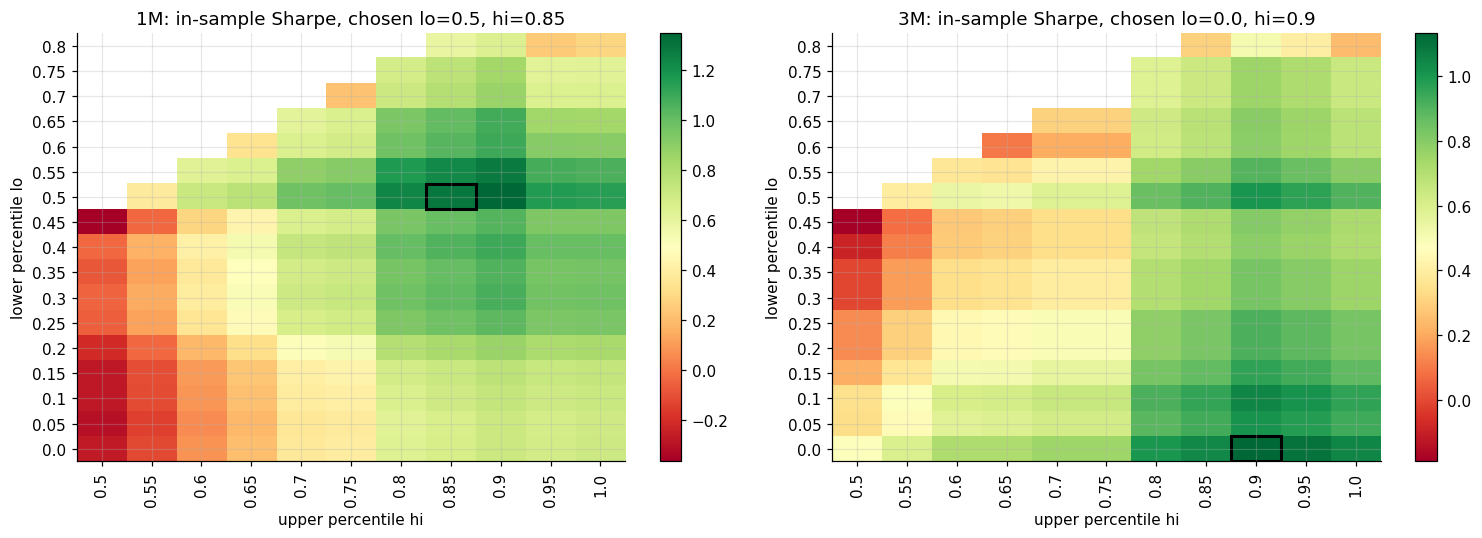

swap        period     strategy   n  active  mean  Sharpe     t  worst  max DD
  1M     in-sample always short 132    1.00  3.49    0.70  2.32 -51.35 -118.08
  1M     in-sample         rule 132    0.35  3.75    1.29  4.29 -19.95  -22.82
  1M out-of-sample always short 104    1.00 -0.14   -0.04 -0.11 -56.44 -107.25
  1M out-of-sample         rule 104    0.13  0.69    0.50  1.47 -12.98  -19.78
  3M     in-sample always short  44    1.00  7.64    1.05  3.48 -34.28  -41.19
  3M     in-sample         rule  44    0.95  8.05    1.13  3.76 -34.28  -34.28
  3M out-of-sample always short  34    1.00  3.18    0.40  1.18 -43.09  -43.09
  3M out-of-sample         rule  34    1.00  3.18    0.40  1.18 -43.09  -43.09


In [8]:
LO = np.round(np.arange(0.0, 0.81, 0.05), 2); HI = np.round(np.arange(0.5, 1.001, 0.05), 2)
def sharpe(x, per_year): x = np.asarray(x, float); return x.mean() / x.std() * np.sqrt(per_year) if x.std() > 0 else np.nan
def rule(d, lo, hi, col): return np.where((d.cor_pct >= lo) & (d.cor_pct <= hi), d[col], 0.0)
results, chosen = [], {}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (lab, step, col, py) in zip(axes, [("1M", H1, "crp1", 12), ("3M", H3, "crp3", 4)]):
    S_ = df.iloc[::step].dropna(subset=[col, "cor_pct"]).copy()
    ISd, OOd = S_[S_.index < SPLIT], S_[S_.index >= SPLIT]
    g = pd.DataFrame([[sharpe(rule(ISd, lo, hi, col), py) if hi > lo else np.nan for hi in HI] for lo in LO], index=LO, columns=HI)
    nb = g.rolling(3, center=True, min_periods=1).median().T.rolling(3, center=True, min_periods=1).median().T
    lo_b, hi_b = nb.where(g.notna()).stack().idxmax(); chosen[lab] = (lo_b, hi_b)
    im = ax.imshow(g.values, aspect="auto", cmap="RdYlGn", origin="lower")
    ax.set_xticks(range(len(HI))); ax.set_xticklabels(HI, rotation=90); ax.set_yticks(range(len(LO))); ax.set_yticklabels(LO)
    ax.add_patch(plt.Rectangle((list(HI).index(hi_b) - 0.5, list(LO).index(lo_b) - 0.5), 1, 1, fill=False, lw=2))
    ax.set_xlabel("upper percentile hi"); ax.set_ylabel("lower percentile lo"); ax.set_title(f"{lab}: in-sample Sharpe, chosen lo={lo_b}, hi={hi_b}")
    plt.colorbar(im, ax=ax)
    for nm, d in [("in-sample", ISd), ("out-of-sample", OOd)]:
        for sl, x in [("always short", d[col].values), ("rule", rule(d, lo_b, hi_b, col))]:
            cum = np.cumsum(x)
            results.append({"swap": lab, "period": nm, "strategy": sl, "n": len(x), "active": (x != 0).mean(),
                            "mean": x.mean(), "Sharpe": sharpe(x, py), "t": x.mean() / x.std() * np.sqrt(len(x)),
                            "worst": x.min(), "max DD": (cum - np.maximum.accumulate(cum)).min()})
plt.tight_layout(); plt.show()
print(pd.DataFrame(results).round(2).to_string(index=False))

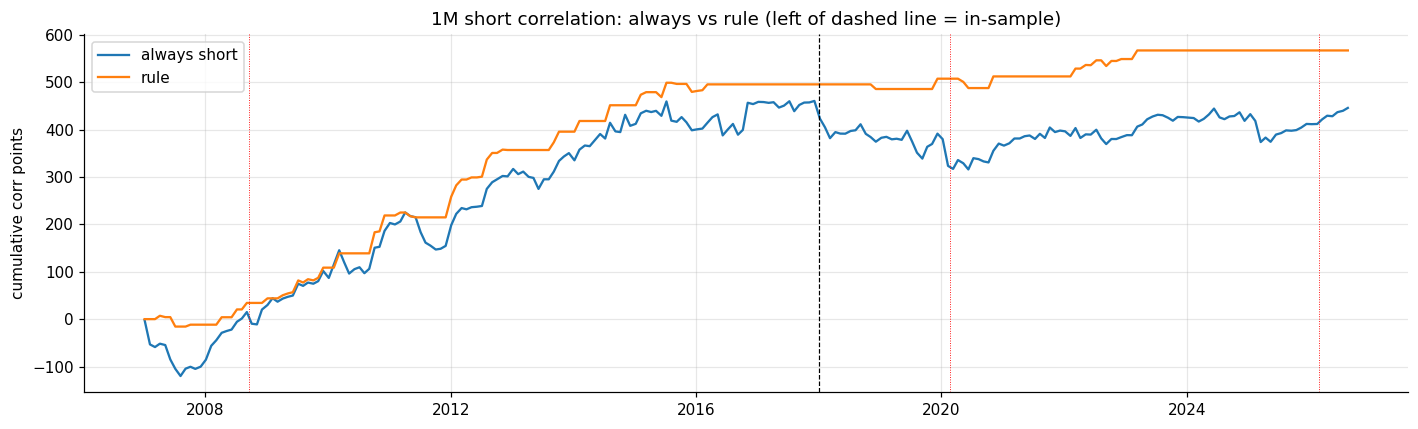

GFC      months 8: always short  +42.3 pts | rule  +23.4 pts
COVID    months 3: always short  -44.1 pts | rule   +0.0 pts
Mar 2026 months 2: always short  +10.1 pts | rule   +0.0 pts

rule today: COR1M percentile 3% -> flat


In [9]:
A = df.iloc[::H1].dropna(subset=["crp1", "cor_pct"]).copy()
A["rule"] = rule(A, *chosen["1M"], "crp1")
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(A.index, A.crp1.cumsum(), label="always short"); ax.plot(A.index, A.rule.cumsum(), label="rule")
ax.axvline(SPLIT, c="k", ls="--", lw=0.8); ax.legend(); ax.set_ylabel("cumulative corr points")
for d in ["2008-09-15", "2020-02-24", "2026-03-02"]: ax.axvline(pd.Timestamp(d), c="r", lw=0.6, ls=":")
ax.set_title("1M short correlation: always vs rule (left of dashed line = in-sample)"); plt.tight_layout(); plt.show()
for lab, a, b in [("GFC", "2008-08-01", "2009-03-31"), ("COVID", "2020-02-01", "2020-04-30"), ("Mar 2026", "2026-02-01", "2026-04-15")]:
    w = A.loc[a:b]
    print(f"{lab:8s} months {len(w)}: always short {w.crp1.sum():+6.1f} pts | rule {w.rule.sum():+6.1f} pts")
print(f"\nrule today: COR1M percentile {df.cor_pct.iloc[-1]:.0%} -> {'SHORT' if chosen['1M'][0] <= df.cor_pct.iloc[-1] <= chosen['1M'][1] else 'flat'}")

**Costs.** A real dispersion trade crosses bid-ask on SPX options and ~50 single-stock options and re-hedges deltas.
As a rough stress, charge a flat k correlation points per active period.

In [10]:
for lab, step, col, py in [("1M", H1, "crp1", 12), ("3M", H3, "crp3", 4)]:
    O = df.iloc[::step].dropna(subset=[col, "cor_pct"]); O = O[O.index >= SPLIT]
    r = rule(O, *chosen[lab], col)
    for k in [0, 1, 2, 3, 4]:
        print(f"{lab} cost {k} pt: out-of-sample Sharpe rule {sharpe(np.where(r != 0, r - k, 0), py):+.2f} | always short {sharpe(O[col] - k, py):+.2f}")

1M cost 0 pt: out-of-sample Sharpe rule +0.50 | always short -0.04
1M cost 1 pt: out-of-sample Sharpe rule +0.41 | always short -0.29
1M cost 2 pt: out-of-sample Sharpe rule +0.32 | always short -0.55
1M cost 3 pt: out-of-sample Sharpe rule +0.22 | always short -0.81
1M cost 4 pt: out-of-sample Sharpe rule +0.12 | always short -1.06
3M cost 0 pt: out-of-sample Sharpe rule +0.40 | always short +0.40
3M cost 1 pt: out-of-sample Sharpe rule +0.28 | always short +0.28
3M cost 2 pt: out-of-sample Sharpe rule +0.15 | always short +0.15
3M cost 3 pt: out-of-sample Sharpe rule +0.02 | always short +0.02
3M cost 4 pt: out-of-sample Sharpe rule -0.10 | always short -0.10
